# Portuguese Bank Marketing Prediction

## Project Overview
The objective of this project is to analyse customer
marketing campaign data and develop Machine Learning
models to predict whether a customer will subscribe
to a bank term deposit.

### Domain
Banking and Finance

### Project Type
Binary Classification

### Dataset
Portuguese Bank Marketing Dataset

# TASK 1

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import os
import warnings

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
df=pd.read_csv("C:/Users/user/Desktop/PRCP-1000-ProtugeseBank/Data/bank-additional/bank-additional-full.csv",sep=';')

In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [6]:
df.shape

(41188, 21)

In [7]:
df.describe(include='all')

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.00000,41188,41188,41188,41188,41188,41188,41188,41188,41188,...,41188.000000,41188.000000,41188.000000,41188,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188
unique,NaN,12,4,8,3,3,3,2,10,5,...,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2
top,NaN,admin.,married,university.degree,no,yes,no,cellular,may,thu,...,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no
freq,NaN,10422,24928,12168,32588,21576,33950,26144,13769,8623,...,NaN,NaN,NaN,35563,NaN,NaN,NaN,NaN,NaN,36548
mean,40.02406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.567593,962.475454,0.172963,NaN,0.081886,93.575664,-40.502600,3.621291,5167.035911,NaN
std,10.42125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.770014,186.910907,0.494901,NaN,1.570960,0.578840,4.628198,1.734447,72.251528,NaN
min,17.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,0.000000,0.000000,NaN,-3.400000,92.201000,-50.800000,0.634000,4963.600000,NaN
25%,32.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,999.000000,0.000000,NaN,-1.800000,93.075000,-42.700000,1.344000,5099.100000,NaN
50%,38.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.000000,999.000000,0.000000,NaN,1.100000,93.749000,-41.800000,4.857000,5191.000000,NaN
75%,47.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.000000,999.000000,0.000000,NaN,1.400000,93.994000,-36.400000,4.961000,5228.100000,NaN


In [8]:
df.shape[0] # rows

41188

In [9]:
df.shape[1] # coloumns

21

In [10]:
pip install scikit-learn xgboost joblib

Note: you may need to restart the kernel to use updated packages.


### Data Cleaning

In [11]:
df.isnull().sum()  # missing or null values


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(12)

In [13]:
df=df.drop_duplicates()

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.dtypes

age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

In [16]:
df.nunique()   # to find unique values

age                 78
job                 12
marital              4
education            8
default              3
housing              3
loan                 3
contact              2
month               10
day_of_week          5
duration          1544
campaign            42
pdays               27
previous             8
poutcome             3
emp.var.rate        10
cons.price.idx      26
cons.conf.idx       26
euribor3m          316
nr.employed         11
y                    2
dtype: int64

In [17]:
df['y'].value_counts()

y
no     36537
yes     4639
Name: count, dtype: int64

In [18]:
df["y"].value_counts(normalize=True) * 100

y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64

## Initial Dataset Observations

1. The dataset contains 41,176 customer records
   and 21 columns.

2. The dataset contains numerical and categorical
   variables.

3. The dataset had 12 duplicates that were removed during data cleaning process

4. The target variable is 'y', which represents
   whether a customer subscribed to a term deposit.

5. The target variable contains two classes:
   yes and no.

6. Approximately 88.73% of customers did not
   subscribe, while 11.27% subscribed.

7. The dataset exhibits significant class imbalance.
   Therefore, accuracy alone will not be a sufficient
   evaluation metric.

8. Multiple categorical variables require encoding
   before machine learning model training.

### Exploratory Data Analysis


In [19]:
# how many unknown values exist in categorical coloumn 
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"{col}: {(df[col] == 'unknown').sum()}")

job: 330
marital: 80
education: 1730
default: 8596
housing: 990
loan: 990
contact: 0
month: 0
day_of_week: 0
poutcome: 0
y: 0


In [20]:
# unknown percentage
unknown_report = pd.DataFrame({
    "Unknown Count": (df == "unknown").sum(),
    "Unknown Percentage": (
        (df == "unknown").sum() / len(df)
    ) * 100
})

display(unknown_report[unknown_report["Unknown Count"] > 0])

,Unknown Count,Unknown Percentage
job,330,0.801438
marital,80,0.194288
education,1730,4.201477
default,8596,20.876239
housing,990,2.404313
loan,990,2.404313


## Unknown Values Analysis

The dataset contains unknown values in six categorical
columns.

Key observations:

1. The default column has the highest number of unknown
   values (8,596), representing approximately 20.88%.

2. Education contains 1,730 unknown values (4.20%).

3. Housing and loan each contain 990 unknown values
   (2.40%).

4. Job contains 330 unknown values (0.80%).

5. Marital status contains only 80 unknown values
   (0.19%).

### Treatment Strategy

Unknown values will initially be retained as a separate
categorical level.

This approach avoids unnecessary data loss and allows
the machine learning model to evaluate whether unknown
information has predictive value.

### Age distribution histogram

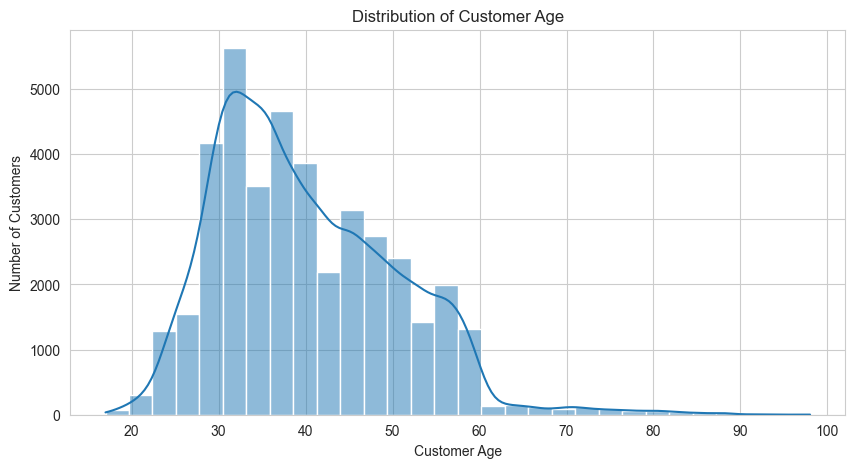

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df,x="age",bins=30, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.show()

In [22]:
print('maximum_age:',df['age'].max())
print('minimum_age:',df['age'].min())
print('Average:',df['age'].mean())
print('median_age:',df['age'].median())
print('most common age:',df['age'].mode(0))

maximum_age: 98
minimum_age: 17
Average: 40.02380027200311
median_age: 38.0
most common age: 0    31
Name: age, dtype: int64


### Age distribution by subscription

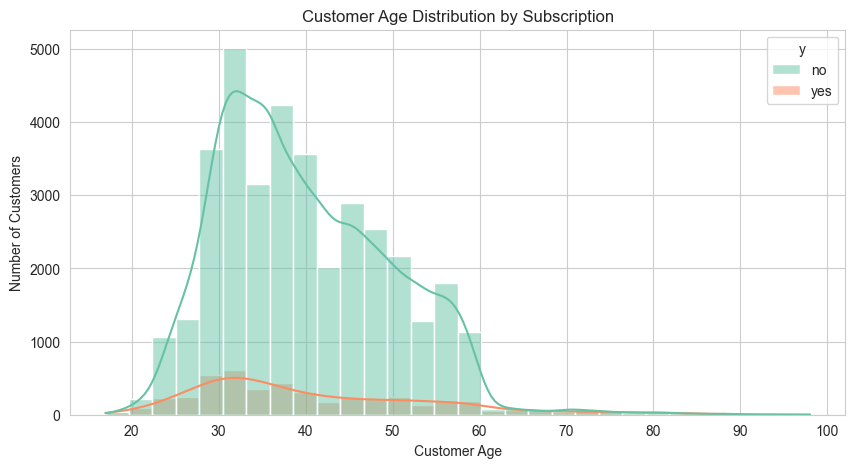

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df,x="age",hue="y",bins=30,kde=True,element='bars',palette='Set2')

plt.title("Customer Age Distribution by Subscription")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.show()

### Job-wise subscription analysis

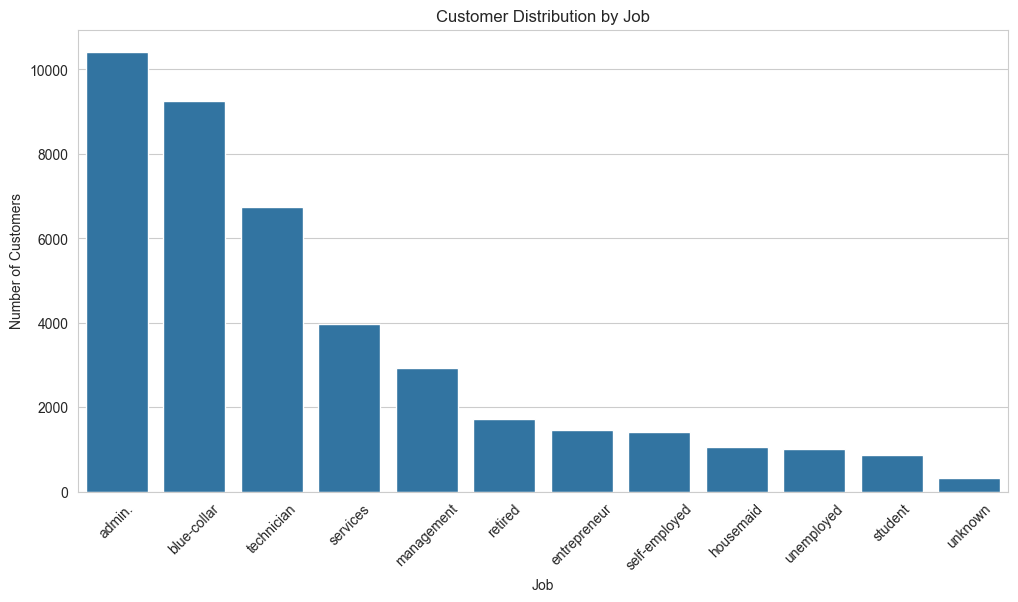

In [24]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df,x="job",order=df["job"].value_counts().index)

plt.title("Customer Distribution by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

### Job-wise subscription count

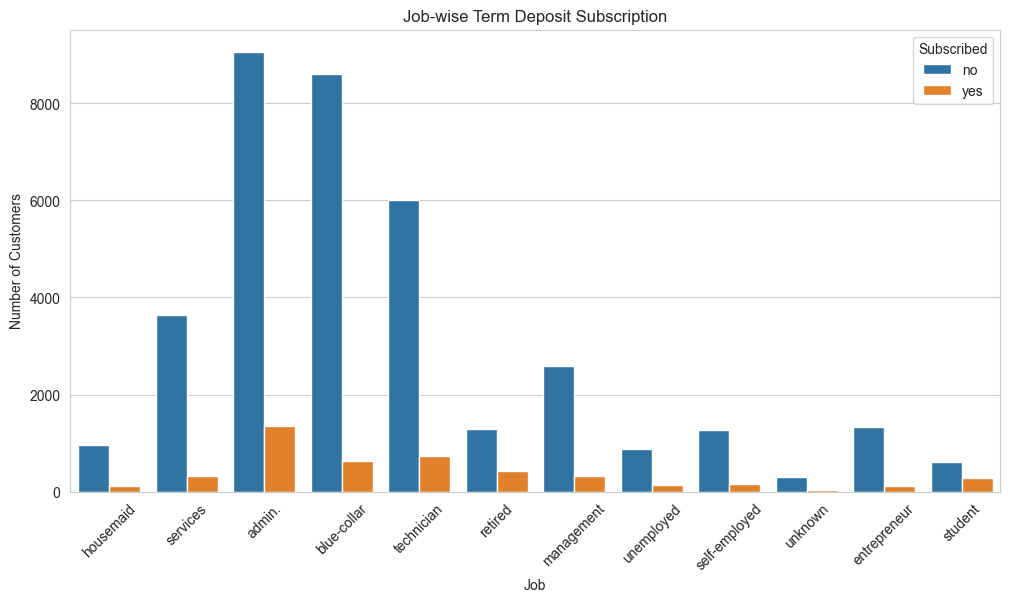

In [25]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df,x="job",hue="y")

plt.title("Job-wise Term Deposit Subscription")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.legend(title="Subscribed")

plt.show()

### subscription percentage by job

In [26]:
job_analysis = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

job_analysis = job_analysis.sort_values(
    by="yes",
    ascending=False
)

display(job_analysis.round(2))

y,no,yes
job,,
student,68.57,31.43
retired,74.74,25.26
unemployed,85.80,14.20
admin.,87.03,12.97
management,88.78,11.22
unknown,88.79,11.21
technician,89.17,10.83
self-employed,89.51,10.49
housemaid,90.00,10.00


### subscription rate

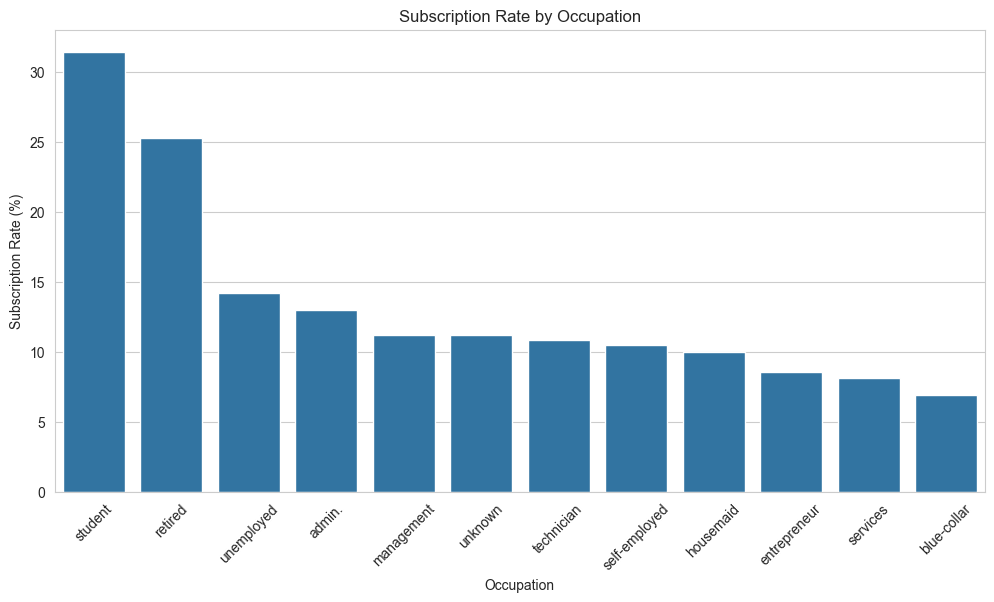

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=job_analysis.index,
    y=job_analysis["yes"]
)

plt.title("Subscription Rate by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)

plt.show()

### Education-wise subscription analysis

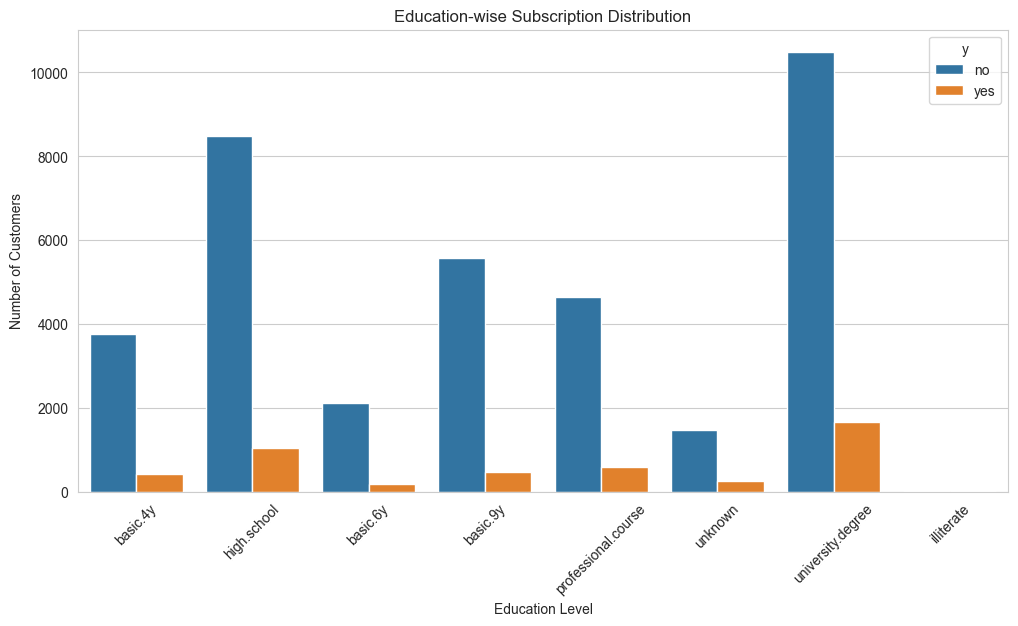

In [28]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="education",
    hue="y"
)

plt.title("Education-wise Subscription Distribution")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

Subscription percentage

In [29]:
education_analysis = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

education_analysis = education_analysis.sort_values(
    by="yes",
    ascending=False
)

display(education_analysis.round(2))

y,no,yes
education,,
illiterate,77.78,22.22
unknown,85.49,14.51
university.degree,86.28,13.72
professional.course,88.65,11.35
high.school,89.16,10.84
basic.4y,89.75,10.25
basic.6y,91.79,8.21
basic.9y,92.18,7.82


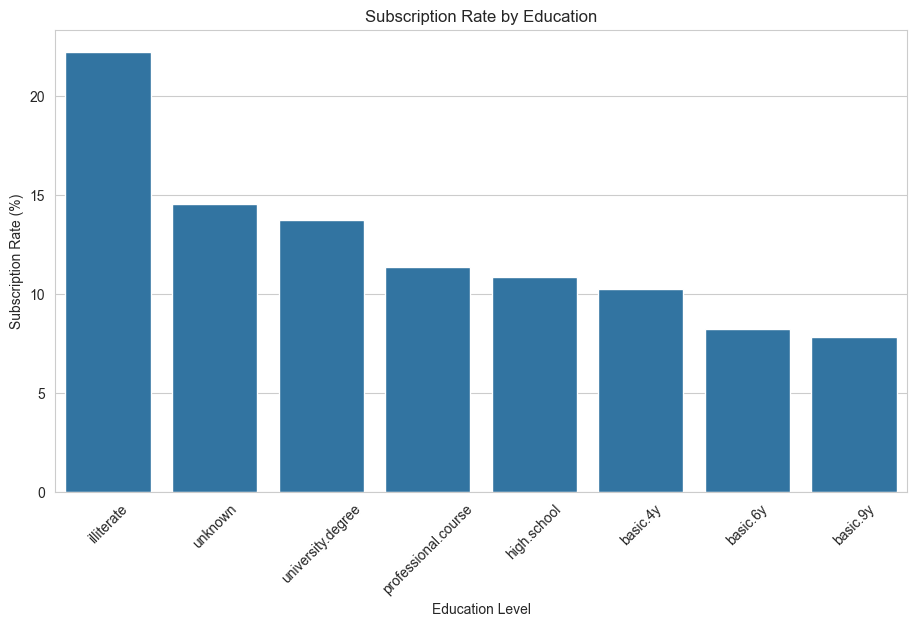

In [30]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=education_analysis.index,
    y=education_analysis["yes"]
)

plt.title("Subscription Rate by Education")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)

plt.show()

Marital status analysis

In [31]:
marital_analysis = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

display(marital_analysis.round(2))

y,no,yes
marital,,
divorced,89.68,10.32
married,89.84,10.16
single,85.99,14.01
unknown,85.00,15.00


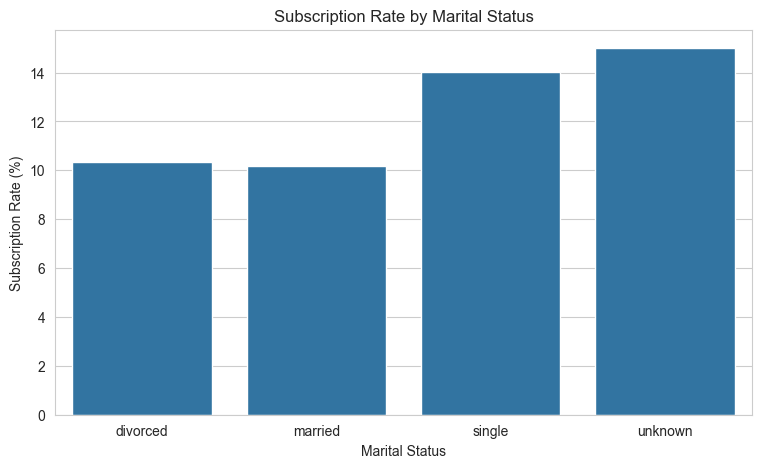

In [32]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=marital_analysis.index,
    y=marital_analysis["yes"]
)

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")

plt.show()

### Demographic Analysis – Key Findings

1. **Age:** The average customer age is approximately 40 years, with a median age of 38 years. Customers range from 17 to 98 years old.

2. **Job:** Students have the highest subscription rate at 31.43%, followed by retired customers at 25.26%.

3. **Education:** Customers with illiterate education have a subscription rate of 22.22%, while university degree holders have a subscription rate of 13.72%.

4. **Marital Status:** Single customers have a subscription rate of 14.01%, compared with 10.16% for married customers and 10.32% for divorced customers.

These observations indicate that customer demographic characteristics are associated with differences in term deposit subscription rates.

## Campaign Analysis

Contact method analysis

Does cellular or telephone communication generate more subscriptions?

In [33]:
contact_analysis = pd.crosstab(
    df["contact"],
    df["y"],
    normalize="index"
) * 100

display(contact_analysis.round(2))

y,no,yes
contact,,
cellular,85.26,14.74
telephone,94.77,5.23


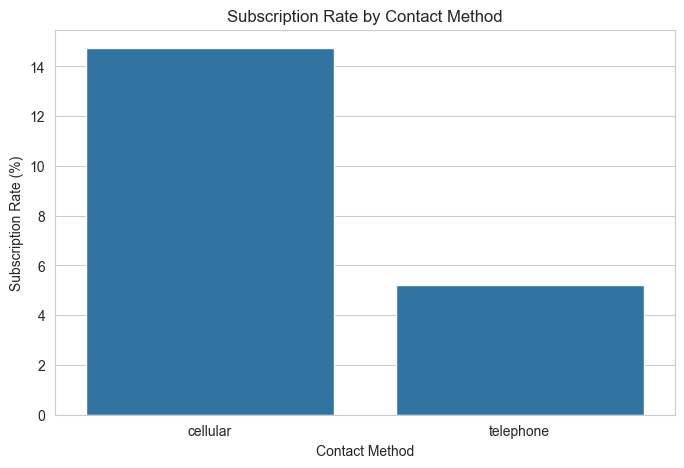

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contact_analysis.index,
    y=contact_analysis["yes"]
)

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")

plt.show()

Month-wise subscription analysis

Which months have higher term deposit subscription rates?

In [35]:
month_analysis = pd.crosstab(
    df["month"],
    df["y"],
    normalize="index"
) * 100

month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_analysis = month_analysis.reindex(month_order)

display(month_analysis.round(2))

y,no,yes
month,,
jan,NaN,NaN
feb,NaN,NaN
mar,49.45,50.55
apr,79.51,20.49
may,93.56,6.44
jun,89.49,10.51
jul,90.96,9.04
aug,89.39,10.61
sep,55.09,44.91


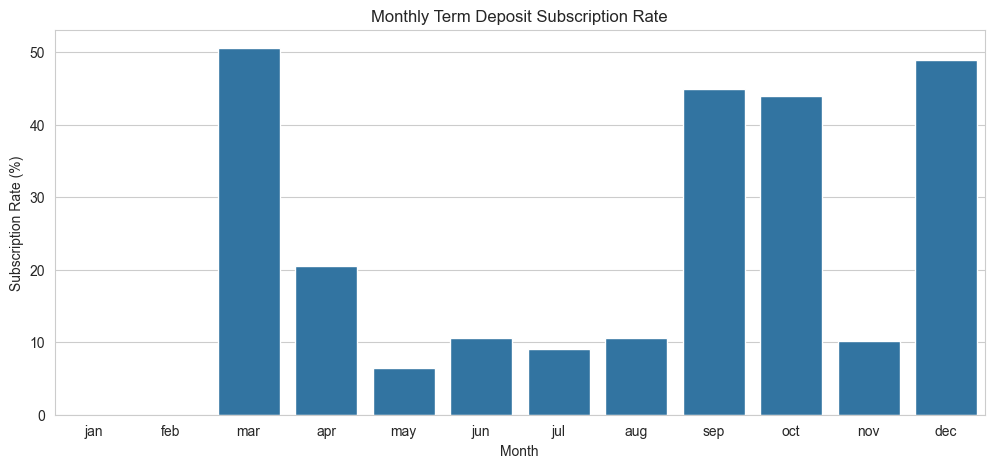

In [36]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=month_analysis.index,
    y=month_analysis["yes"]
)

plt.title("Monthly Term Deposit Subscription Rate")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")

plt.show()

Day-of-week analysis

Which weekdays produce better subscription rates?

In [37]:
day_analysis = pd.crosstab(
    df["day_of_week"],
    df["y"],
    normalize="index"
) * 100

day_order = ["mon", "tue", "wed", "thu", "fri"]

day_analysis = day_analysis.reindex(day_order)

display(day_analysis.round(2))

y,no,yes
day_of_week,,
mon,90.05,9.95
tue,88.21,11.79
wed,88.33,11.67
thu,87.89,12.11
fri,89.19,10.81


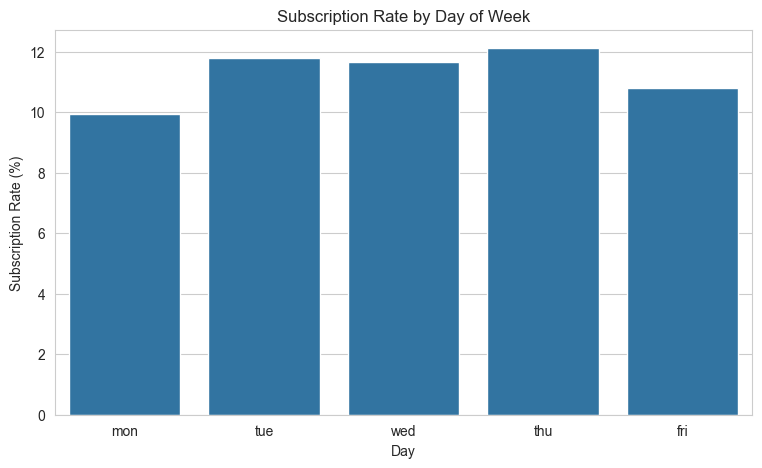

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=day_analysis.index,
    y=day_analysis["yes"]
)

plt.title("Subscription Rate by Day of Week")
plt.xlabel("Day")
plt.ylabel("Subscription Rate (%)")

plt.show()

Number of contacts in the current campaign

Does repeatedly contacting customers improve conversion?

In [39]:
campaign_analysis = df.groupby("campaign").agg(
    Total_Customers=("y", "count"),
    Subscribers=("y", lambda x: (x == "yes").sum())
)

campaign_analysis["Subscription_Rate"] = (
    campaign_analysis["Subscribers"] /
    campaign_analysis["Total_Customers"]
) * 100

display(campaign_analysis.head(15).round(2))

,Total_Customers,Subscribers,Subscription_Rate
campaign,,,
1,17634,2299,13.04
2,10568,1211,11.46
3,5340,574,10.75
4,2650,249,9.40
5,1599,120,7.50
6,979,75,7.66
7,629,38,6.04
8,400,17,4.25
9,283,17,6.01


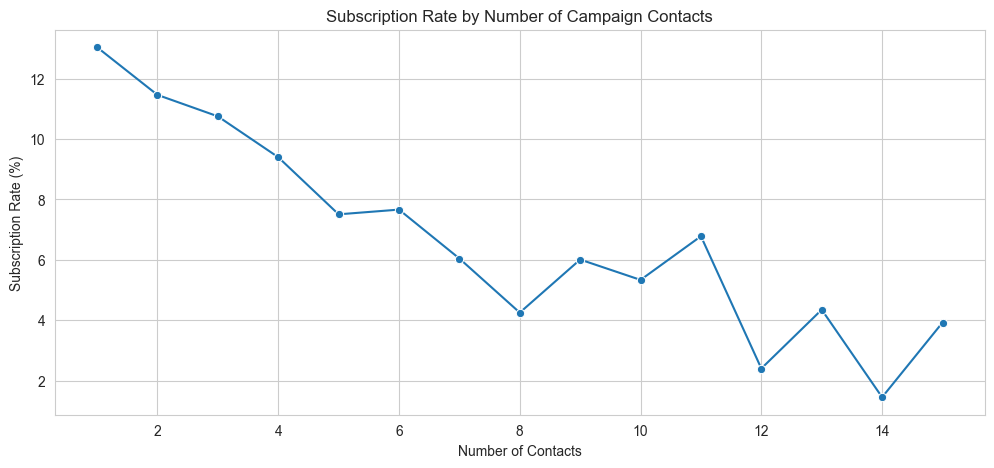

In [40]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=campaign_analysis.head(15),
    x=campaign_analysis.head(15).index,
    y="Subscription_Rate",
    marker="o"
)

plt.title("Subscription Rate by Number of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")

plt.show()

Previous campaign outcome

Are customers who responded positively to previous campaigns more likely to subscribe again?

In [41]:
previous_outcome = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

display(previous_outcome.round(2))

y,no,yes
poutcome,,
failure,85.77,14.23
nonexistent,91.17,8.83
success,34.89,65.11


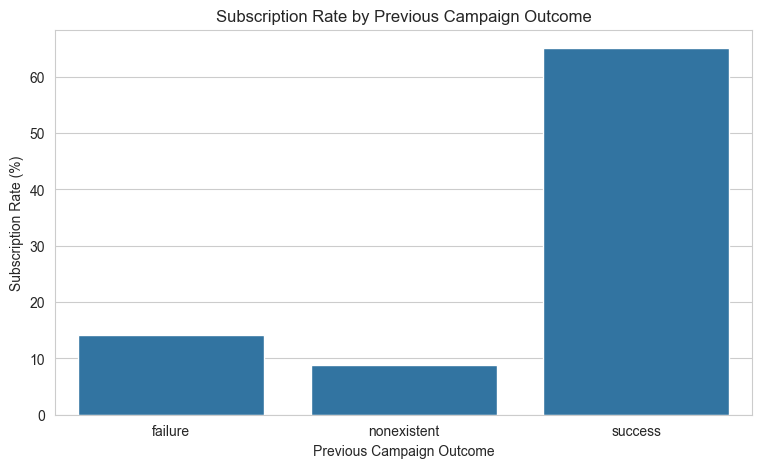

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=previous_outcome.index,
    y=previous_outcome["yes"]
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.show()

Previous contact frequency

In [43]:
previous_analysis = df.groupby("previous").agg(
    Total_Customers=("y", "count"),
    Subscribers=("y", lambda x: (x == "yes").sum())
)

previous_analysis["Subscription_Rate"] = (
    previous_analysis["Subscribers"] /
    previous_analysis["Total_Customers"]
) * 100

display(previous_analysis.round(2))

,Total_Customers,Subscribers,Subscription_Rate
previous,,,
0,35551,3140,8.83
1,4561,967,21.20
2,754,350,46.42
3,216,128,59.26
4,70,38,54.29
5,18,13,72.22
6,5,3,60.00
7,1,0,0.00


Days since previous contact

In [44]:
df["previous_contact_status"] = np.where(
    df["pdays"] == 999,
    "Never Contacted",
    "Previously Contacted"
)

pdays_analysis = pd.crosstab(
    df["previous_contact_status"],
    df["y"],
    normalize="index"
) * 100

display(pdays_analysis.round(2))

y,no,yes
previous_contact_status,,
Never Contacted,90.74,9.26
Previously Contacted,36.17,63.83


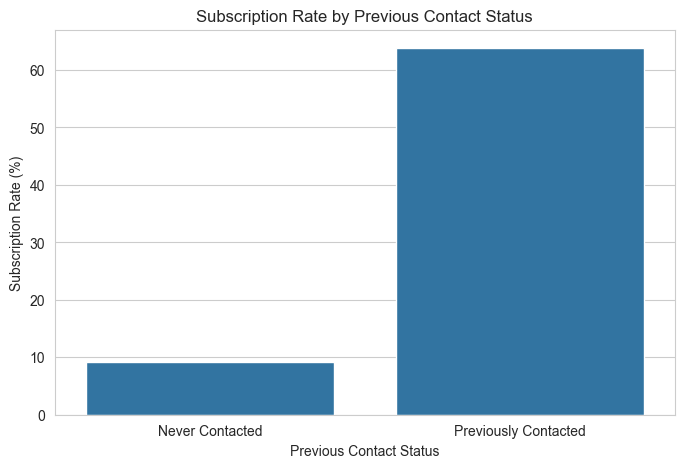

In [45]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=pdays_analysis.index,
    y=pdays_analysis["yes"]
)

plt.title("Subscription Rate by Previous Contact Status")
plt.xlabel("Previous Contact Status")
plt.ylabel("Subscription Rate (%)")

plt.show()

Economic Indicators Analysis

Do changes in economic conditions correspond with differences in customer subscription rates?

Statistical analysis

In [46]:
economic_columns = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

economic_summary = df[economic_columns].describe()

display(economic_summary)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,0.081922,93.575720,-40.502863,3.621293,5167.034870
std,1.570883,0.578839,4.627860,1.734437,72.251364
min,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,1.400000,94.767000,-26.900000,5.045000,5228.100000


Correlation analysis

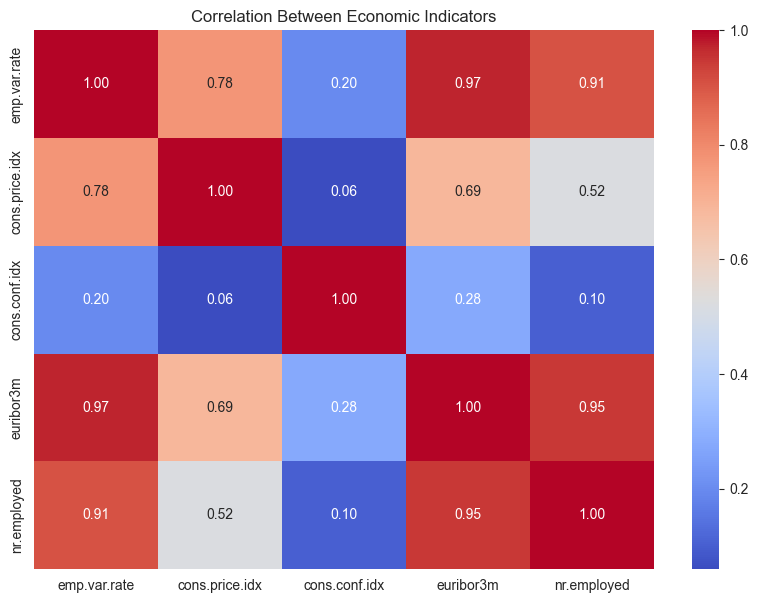

In [47]:
plt.figure(figsize=(10, 7))

economic_corr = df[economic_columns].corr()

sns.heatmap(
    economic_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Economic Indicators")

plt.show()

Economic indicators by subscription status

In [48]:
economic_target_analysis = df.groupby("y")[
    economic_columns
].mean().T

display(economic_target_analysis.round(3))

y,no,yes
emp.var.rate,0.249,-1.233
cons.price.idx,93.604,93.355
cons.conf.idx,-40.593,-39.791
euribor3m,3.811,2.123
nr.employed,5176.166,5095.120


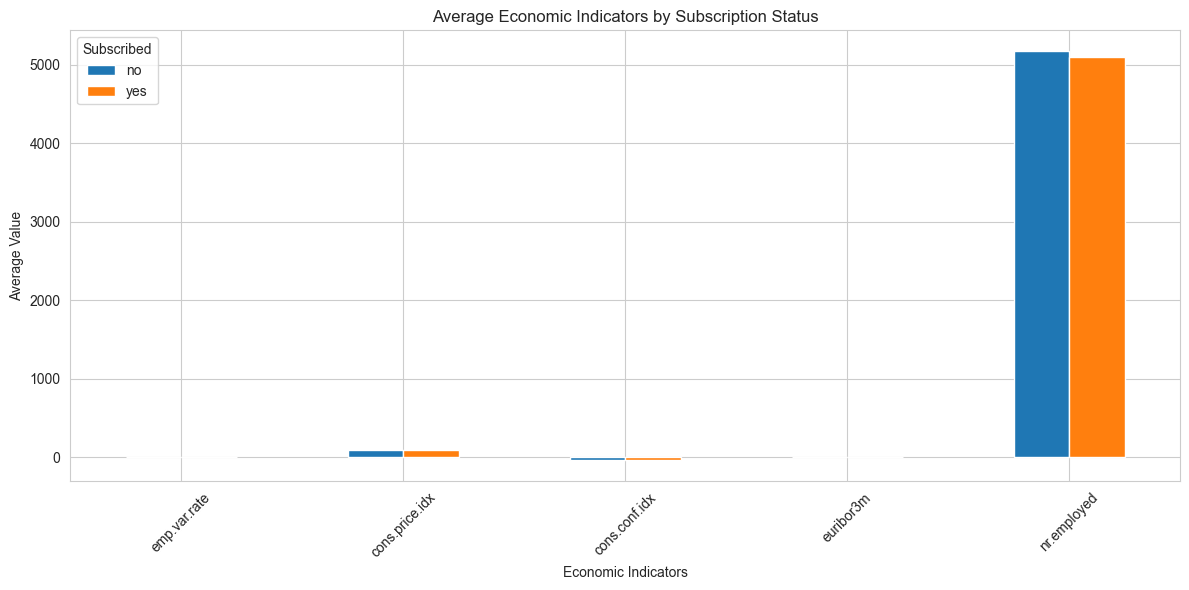

In [49]:
economic_target_analysis.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Economic Indicators by Subscription Status")
plt.xlabel("Economic Indicators")
plt.ylabel("Average Value")
plt.xticks(rotation=45)

plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

Distribution of economic indicators

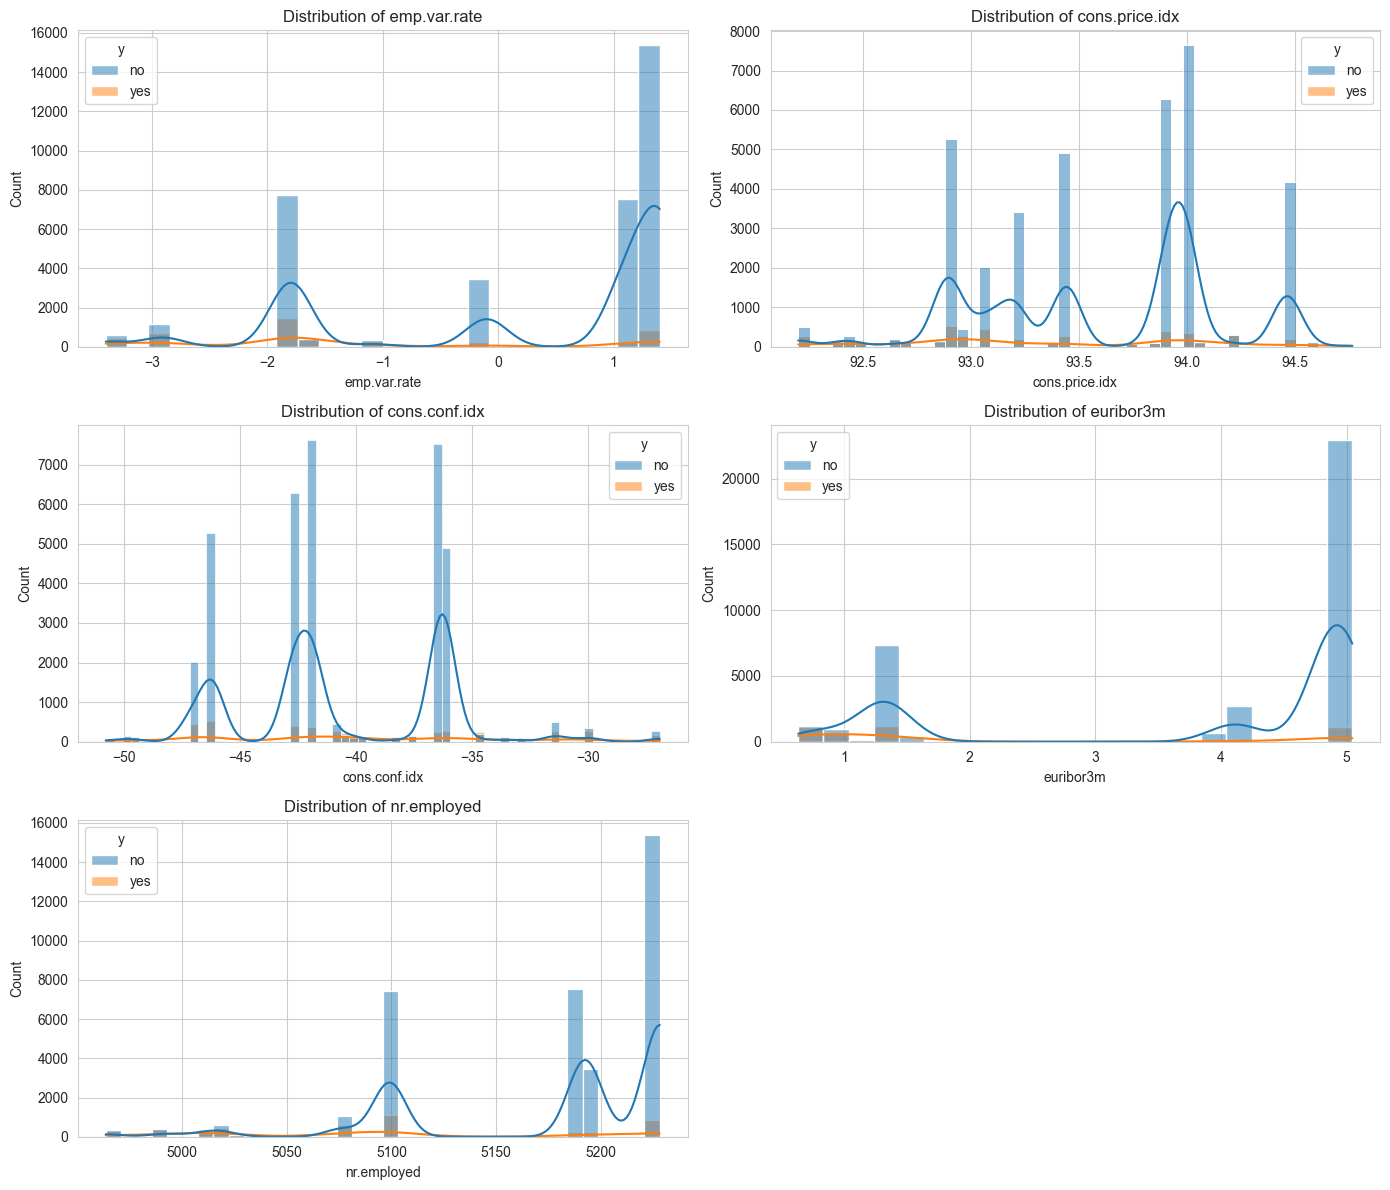

In [50]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for col, ax in zip(economic_columns, axes.flatten()):
    sns.histplot(
        data=df,
        x=col,
        hue="y",
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

## Campaign Analysis – Key Findings

1. The contact method with the highest subscription
   rate was Cellular.

2. The month with the highest subscription rate was
   March.

3. The weekday with the highest subscription rate was
   Thursday.

4. Subscription rates across campaign contact counts
   showed repeatedly contacting customers will improve conversion.

5. Customers with a previous successful campaign
   outcome had highest success subscription behaviour.

6. Previously contacted customers showed Higher
   subscription behaviour compared with customers
   never contacted.

## Economic Indicators – Key Findings

1. The economic indicator with the highest correlation
   with Euribor was emp var.rate.

2. Customers who subscribed showed different average
   economic indicator values for subscribed and non-subscribed customers.

3. The correlation analysis identified strong positive and weak 
   relationships between economic indicators.

4. Economic conditions may influence customer
   subscription behaviour, but correlation alone
   does not establish causation.

### Feature Engineering & Data Preprocessing

In [51]:
model_df = df.copy()

print("Original dataset shape:", df.shape)
print("Modelling dataset shape:", model_df.shape)

Original dataset shape: (41176, 22)
Modelling dataset shape: (41176, 22)


Target variable is y with yes and no

duration coloumn to be removed as it causes data leakage and mentioned in the pdf

In [52]:
X = df.drop(
    ['campaign', 'duration', 'previous_contact_status'],
    axis=1
)

In [53]:
X.shape

(41176, 19)

In [54]:

X = df.drop(columns=['y', 'campaign', 'duration'])


y = df['y'].map({
    'no': 0,
    'yes': 1
})

In [55]:
X = X.drop(columns=['previous_contact_status'])

In [56]:
from sklearn.model_selection import train_test_split

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X,y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [58]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [61]:
numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

print("Total numerical:", len(numerical_columns))
print("Total categorical:", len(categorical_columns))

Numerical columns: ['age', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Total numerical: 8
Total categorical: 10


In [62]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [64]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [65]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (32940, 61)
Testing: (8236, 61)


# TASK 2

## Logistic Regression

In [66]:
from sklearn.linear_model import LogisticRegression

In [67]:
log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

log_model.fit(X_train_processed, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [68]:
y_pred_log = log_model.predict(X_test_processed)

In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [70]:
print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_test, y_pred_log))

print("Precision:", precision_score(y_test, y_pred_log))

print("Recall:", recall_score(y_test, y_pred_log))

print("F1 Score:", f1_score(y_test, y_pred_log))

Logistic Regression Results
Accuracy: 0.8306216610004856
Precision: 0.359591100420926
Recall: 0.6443965517241379
F1 Score: 0.4615978386723273


In [71]:
print(classification_report(
    y_test,
    y_pred_log,
    target_names=["No Subscription", "Subscription"]
))

                 precision    recall  f1-score   support

No Subscription       0.95      0.85      0.90      7308
   Subscription       0.36      0.64      0.46       928

       accuracy                           0.83      8236
      macro avg       0.65      0.75      0.68      8236
   weighted avg       0.88      0.83      0.85      8236



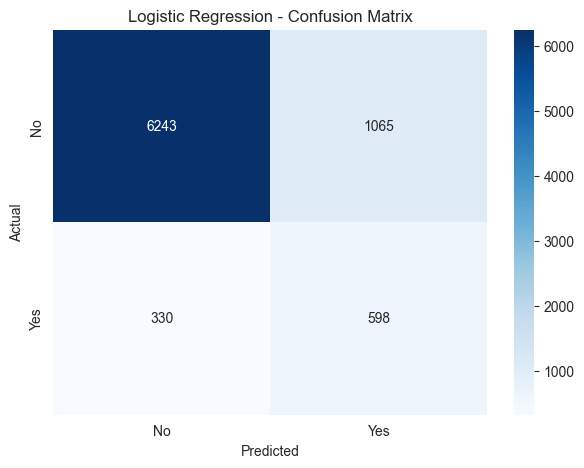

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

## Model 1: Logistic Regression – Results

The Logistic Regression model was trained using
class_weight='balanced' to address class imbalance.

Performance metrics:

- Accuracy: 83.06%
- Precision: 35.96%
- Recall: 64.44%
- F1-score: 46.16%

### Observations

1. The model achieved 83.06% accuracy.
2. The recall of 64.44% indicates that the model
   identifies approximately 64% of actual subscribers.
3. Precision of 35.96% indicates that there are
   considerable false-positive predictions.
4. The F1-score of 46.16% indicates scope for
   improving the balance between precision and recall.

### Conclusion

Logistic Regression provides a baseline classification
model. Further algorithms will be evaluated to identify
a more suitable model for bank marketing predictions.

## Decision Tree Classifier

In [73]:
from sklearn.tree import DecisionTreeClassifier

In [75]:
dtc_model=DecisionTreeClassifier(random_state=42,class_weight="balanced",
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10
)

dtc_model.fit(X_train_processed, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [78]:
y_pred_dtc=dtc_model.predict(X_test_processed)

In [79]:
print("Decision Tree Results")

print("Accuracy:", accuracy_score(y_test, y_pred_dtc))

print("Precision:", precision_score(y_test, y_pred_dtc))

print("Recall:", recall_score(y_test, y_pred_dtc))

print("F1 Score:", f1_score(y_test, y_pred_dtc))

Decision Tree Results
Accuracy: 0.823943661971831
Precision: 0.347010550996483
Recall: 0.6379310344827587
F1 Score: 0.4495064540622627


In [81]:
print(classification_report(
    y_test,
    y_pred_dtc,
    target_names=["No Subscription", "Subscription"]
))

                 precision    recall  f1-score   support

No Subscription       0.95      0.85      0.90      7308
   Subscription       0.35      0.64      0.45       928

       accuracy                           0.82      8236
      macro avg       0.65      0.74      0.67      8236
   weighted avg       0.88      0.82      0.84      8236



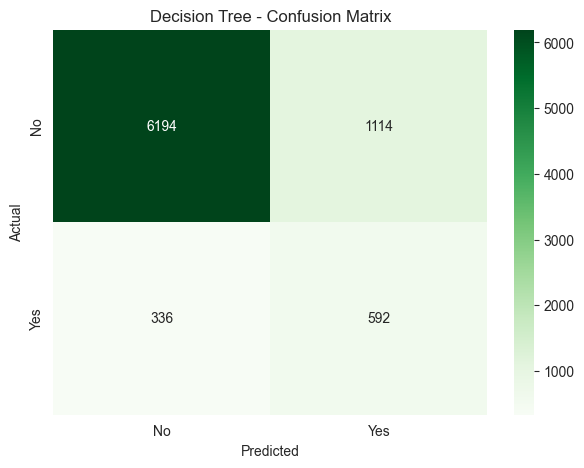

In [83]:
cm_dtc = confusion_matrix(y_test, y_pred_dtc)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dtc,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

### Decision Tree – Model Evaluation

The Decision Tree model achieved an accuracy of 82.39%,
precision of 34.70%, recall of 63.79%, and F1-score of 44.95%.

The model demonstrates reasonable ability to identify potential
subscribers. However, its precision indicates that a considerable
number of predicted positive customers may not subscribe.

Compared with Logistic Regression, the Decision Tree performs
slightly worse across all four evaluation metrics.

## Random Forest

In [84]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

y_pred_rf = rf_model.predict(X_test_processed)

In [85]:
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Subscription", "Subscription"]
))

Random Forest Results
Accuracy: 0.8634045653229723
Precision: 0.4278388278388278
Recall: 0.6293103448275862
F1 Score: 0.5093763628434366
                 precision    recall  f1-score   support

No Subscription       0.95      0.89      0.92      7308
   Subscription       0.43      0.63      0.51       928

       accuracy                           0.86      8236
      macro avg       0.69      0.76      0.72      8236
   weighted avg       0.89      0.86      0.87      8236



### Random Forest – Model Evaluation

The Random Forest classifier achieved an accuracy of 86.34%, precision of 42.78%, recall of 62.93%, and F1-score of 50.94%.

Among the three evaluated models, Random Forest achieved the highest accuracy, precision, and F1-score. Although its recall was marginally lower than Logistic Regression, it provided a better overall balance between identifying potential subscribers and reducing false-positive predictions.

**Conclusion:** Random Forest is the current best-performing model based on the evaluation metrics. It can help the bank prioritize customers who are more likely to subscribe to a term deposit.

ROC-AUC measures how well a model distinguishes subscribers from non-subscribers across different classification thresholds.

In [87]:
from sklearn.metrics import roc_auc_score


y_prob_log = log_model.predict_proba(X_test_processed)[:, 1]
y_prob_dtc = dtc_model.predict_proba(X_test_processed)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

print("Logistic Regression AUC:", roc_auc_score(y_test, y_prob_log))
print("Decision Tree AUC:", roc_auc_score(y_test, y_prob_dtc))
print("Random Forest AUC:", roc_auc_score(y_test, y_prob_rf))

Logistic Regression AUC: 0.8008922083498481
Decision Tree AUC: 0.7894566417530151
Random Forest AUC: 0.8127853214710379


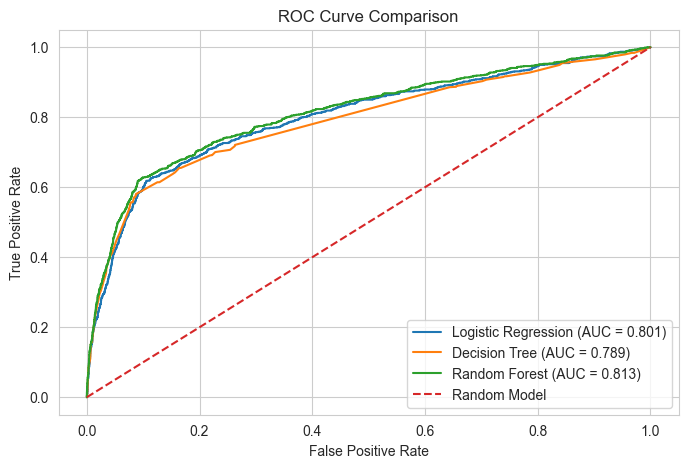

In [89]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc


models = {
    "Logistic Regression": y_prob_log,
    "Decision Tree": y_prob_dtc,
    "Random Forest": y_prob_rf
}


plt.figure(figsize=(8, 5))

for name, predictions in models.items():
    fpr, tpr, thresholds = roc_curve(y_test, predictions)
    score = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {score:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random Model")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

## Model Comparison Report

Three machine learning classification algorithms were implemented to predict whether a customer would subscribe to a term deposit.

The models evaluated were:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The models were evaluated using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

In [92]:
model_comparison = pd.DataFrame({
   
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [0.8306, 0.8239, 0.8634],
    "Precision": [0.3596, 0.3470, 0.4278],
    "Recall": [0.6444, 0.6379, 0.6293],
    "F1 Score": [0.4616, 0.4495, 0.5094],
    "ROC-AUC": [0.8009, 0.7895, 0.8128]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8306,0.3596,0.6444,0.4616,0.8009
1,Decision Tree,0.8239,0.3470,0.6379,0.4495,0.7895
2,Random Forest,0.8634,0.4278,0.6293,0.5094,0.8128


### Model Comparison – Conclusion

Based on the evaluation results, Random Forest achieved the highest Accuracy (86.34%), Precision (42.78%), F1 Score (50.94%) and ROC-AUC (81.28%).

Logistic Regression achieved the highest Recall (64.44%), while Decision Tree showed comparatively lower performance across the evaluation metrics.

Therefore, Random Forest is selected as the best-performing model among the three evaluated algorithms for predicting customers who are likely to subscribe to a term deposit.

The final model selection is based on its overall performance across the evaluation metrics.

# Challenges Faced and Solutions

During the development of the Bank Marketing Prediction model, the following challenges were encountered:

1. **Class Imbalance:** The dataset contained more customers who did not subscribe than customers who subscribed. Class weighting was used to give more importance to the minority class.

2. **Unknown Values:** Several categorical columns contained unknown values. These were retained as categories instead of removing the records.

3. **Categorical Data:** Machine learning algorithms require numerical inputs. One-Hot Encoding was used to convert categorical variables into numerical format.

4. **Feature Scaling:** Numerical features had different scales. StandardScaler was used to standardize numerical features.

5. **Data Leakage:** The duration column was excluded because call duration is not known before contacting a customer. Including it would make the prediction unrealistic for a pre-call marketing campaign.

6. **Model Selection:** Multiple classification algorithms were evaluated using Accuracy, Precision, Recall, F1 Score and ROC-AUC to identify the best-performing model.

# Task 3 – Business Suggestions to the Bank Marketing Team

Based on the data analysis and predictive modelling results, the following suggestions can help the bank improve its term deposit marketing campaigns.

### 1. Target Potential Customers
The bank should use the Random Forest prediction model to identify customers who are more likely to subscribe to term deposits and prioritize them during marketing campaigns.

### 2. Focus on Previous Campaign Outcomes
The bank should consider customers' previous campaign responses when planning future marketing activities. Customers who responded positively to previous campaigns can be prioritized.

### 3. Improve Contact Strategies
The bank should analyze the effectiveness of different communication methods and select suitable contact channels to improve customer engagement.

### 4. Optimize Campaign Timing
The bank should evaluate subscription patterns across different months and days of the week to identify suitable periods for conducting marketing campaigns.

### 5. Avoid Excessive Customer Contact
The bank should avoid contacting customers too frequently, as repeated calls may reduce customer interest and campaign effectiveness.

### 6. Monitor Marketing Campaign Performance
The bank should regularly monitor campaign results, customer responses and subscription rates to improve future marketing strategies.

### Conclusion
By combining customer data analysis with predictive modelling, the bank can improve customer targeting, optimize marketing campaigns and increase the chances of term deposit subscriptions. The Random Forest model can support the marketing team in prioritizing potential customers.